# Module 03: Assignment for 1-D Diffusion Problem - Thawing Permafrost

### 1. Introduction and Background

In this notebook you are going to investigate the impact of three climate change scenarios on our previously developed model of the vertical distribution of temperature in a permafrost soil. 


Again, the equation for 1-dimensional heat diffusion into a soil is presented below:
$$
\rho_s \cdot C_s \cdot \frac{\partial T_s}{\partial t} = \frac{\partial T_s}{\partial z}\left(k_s \cdot \frac{\partial T_s}{\partial z}\right)
$$

where $\rho_s$ (kg/m^3) is the bulk density of the soil, $C_s$ (J/(kg K)) is the heat capacity of the soil, $k_s$ (W/(m K)) is the thermal conductivity of the soil, $T_s$ is the temperature of the soil at some time $t$ and depth in the soil $z$. For the sake of simplicity, we're going to assume that the thermal conductivity is constant. This assumption is not strictly true, as $k_s$ changes with the amount and phase (frozen or liquid) of water in the soil. But it makes the math much simpler and is good starting point for a toy model. Under this assumption we can simplify the above equation to,

$$
\rho_s \cdot C_s \cdot \frac{\partial T_s}{\partial t} = k_s \frac{\partial T_s^2}{\partial^2 z}
$$

Going further, if we also assume that the bulk density ($rho_s$) and heat capacity ($C_s$) are constant, then we can combine them with the thermal conductivity and reduce them to a single parameter that is often referred to as the _thermal diffusivity_ ($D_s$) and has dimensions of m^2/s, 

$$
D_s = \frac{k_s}{\rho_s \cdot C_s}
$$

Substituting into the above, we obtain the following governing equation that our model will solve, 

$$
\frac{\partial T_s}{\partial t} = D_s \frac{\partial T_s^2}{\partial^2 z}
$$

Your __top boundary condition__, we will assume sinusoidal forcing of air temperature superimposed on a linear trend in mean annual temperatures at the surface, with a period of one year. In this notebook we will explore three scenarios. Scenario 1 is a linear increase in mean annual temperature at a rate that results in 1.5 °C of warming by 2100. Scenario 2 is a linear increase in mean annual temperature at a rate that results in 3.0 °C of warming by 2100. Scenario 3 is a linear increase in mean annual temperature at a rate that results in 4.5 °C of warming by 2100. We will start all simulations in 2020. 

Your __bottom boundary condition__, we will assume a constant temperature at the initial mean annual air temperature. 

Yur __initial condition__ will be a constant temperature (isothermal) at the mean annual air temperature. If interested you can copy this notebook and modify these values.

### 2. Initial Setup

Below, we set the values for our spatial domain, simulation period, soil properties, and boundary conditions. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Soil column properties
zs = 500.0 # Depth of soil [cm]
dz = 15.0   # Numerical model layer thickness [cm]

# Soil properties (obtained from https://doi.org/10.1029/2017JF004535)
Cs = 635.0 # Heat capacity of soil/permafrost [J/(kg K)]
ks = 0.25  # Thermal conductivity of soil/permafrost [W/(m K)]
rhos = 920.0 # Bulk density of permafrost [kg/m^3] 

dt = 0.25 # Time step [day]

#### 2.1 Load and Plot the Air Temperature Trends

In [2]:
data = np.loadtxt('PermafrostTemperatureScenarios.csv', delimiter=',', skiprows=1)

t_year = data[:,0]
T_15 = data[:,1]
T_30 = data[:,2]
T_45 = data[:,3]

#display data
print("Time (years):", t_year)
print("Temperature increase 1.5°C:", T_15)
print("Temperature increase 3.0°C:", T_30)
print("Temperature increase 4.5°C:", T_45)

Time (years): [2020. 2021. 2022. 2023. 2024. 2025. 2026. 2027. 2028. 2029. 2030. 2031.
 2032. 2033. 2034. 2035. 2036. 2037. 2038. 2039. 2040. 2041. 2042. 2043.
 2044. 2045. 2046. 2047. 2048. 2049. 2050. 2051. 2052. 2053. 2054. 2055.
 2056. 2057. 2058. 2059. 2060. 2061. 2062. 2063. 2064. 2065. 2066. 2067.
 2068. 2069. 2070. 2071. 2072. 2073. 2074. 2075. 2076. 2077. 2078. 2079.
 2080. 2081. 2082. 2083. 2084. 2085. 2086. 2087. 2088. 2089. 2090. 2091.
 2092. 2093. 2094. 2095. 2096. 2097. 2098. 2099. 2100.]
Temperature increase 1.5°C: [-7.    -6.981 -6.963 -6.944 -6.925 -6.906 -6.888 -6.869 -6.85  -6.831
 -6.813 -6.794 -6.775 -6.756 -6.738 -6.719 -6.7   -6.681 -6.663 -6.644
 -6.625 -6.606 -6.588 -6.569 -6.55  -6.531 -6.513 -6.494 -6.475 -6.456
 -6.438 -6.419 -6.4   -6.381 -6.363 -6.344 -6.325 -6.306 -6.288 -6.269
 -6.25  -6.231 -6.213 -6.194 -6.175 -6.156 -6.138 -6.119 -6.1   -6.081
 -6.063 -6.044 -6.025 -6.006 -5.988 -5.969 -5.95  -5.931 -5.913 -5.894
 -5.875 -5.856 -5.838 -5.819 -5.8   -5

Text(0, 0.5, 'Annual average air temperature [°C]')

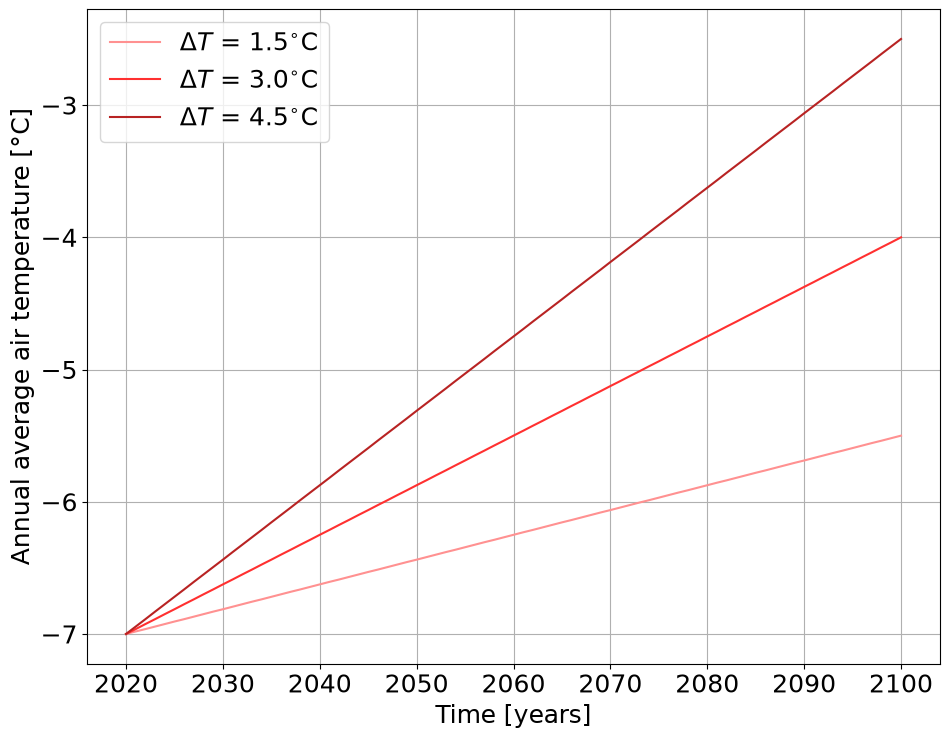

In [3]:
plt.rcParams.update({'font.size': 18})
scenario_colors = ['#ff9191', '#ff3030', '#b82323']

plt.figure(figsize=(11.0,8.5))
plt.plot(t_year,T_15,label='$\\Delta T$ = 1.5${}^{\\circ}$C', color=scenario_colors[0])
plt.plot(t_year,T_30,label='$\\Delta T$ = 3.0${}^{\\circ}$C', color=scenario_colors[1])
plt.plot(t_year,T_45,label='$\\Delta T$ = 4.5${}^{\\circ}$C', color=scenario_colors[2])
plt.legend(loc='upper left')
plt.grid()
plt.xlabel('Time [years]')
plt.ylabel('Annual average air temperature [°C]')

#### 2.2 Setup the Simulation Time Period

In [4]:
#simulation time period
t0 = t_year[0]
tf = t_year[-1]

#time array
t = np.arange(t0,tf+(dt/365),(dt/365))

#number of time steps
Nt = t.size

print('The number of time steps: Nt = ',str(Nt))

The number of time steps: Nt =  116801


### 3. Setup Boundary Conditions

In [5]:
# Boundary conditions
Ttopamp = 35.0
Tbottom = -7.0

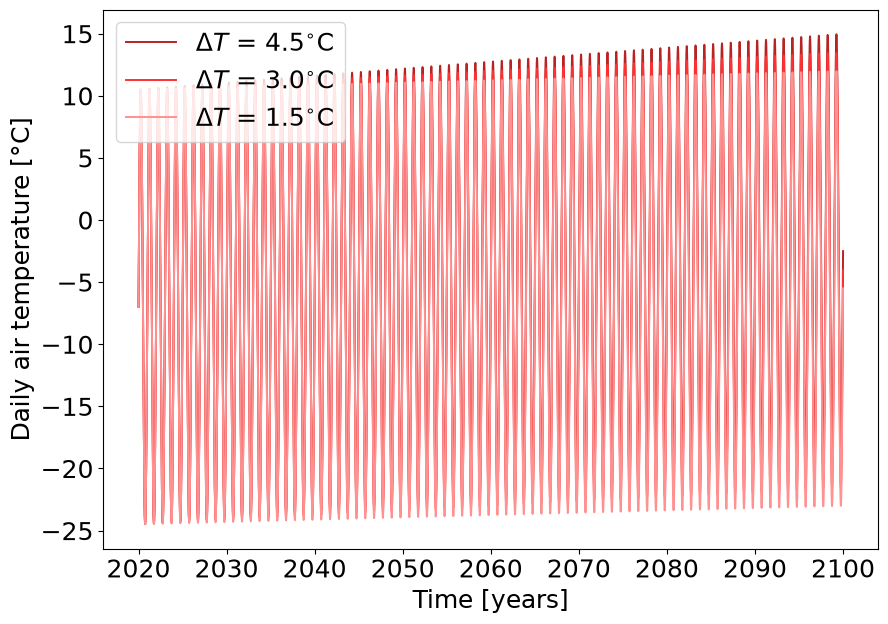

In [6]:
#interpolate the annual average air temperature to daily values and add sinusoidal variation to represent seasonal changes
Ttop_15 = np.interp(t, t_year, T_15) + (Ttopamp/2.0)*np.sin((2.0*np.pi)*t)
Ttop_30 = np.interp(t, t_year, T_30) + (Ttopamp/2.0)*np.sin((2.0*np.pi)*t)
Ttop_45 = np.interp(t, t_year, T_45) + (Ttopamp/2.0)*np.sin((2.0*np.pi)*t)

plt.figure(figsize=(10.0,7.0))
plt.plot(t, Ttop_45, label='$\\Delta T$ = 4.5${}^{\\circ}$C', color=scenario_colors[2], linewidth=1.4)
plt.plot(t, Ttop_30, label='$\\Delta T$ = 3.0${}^{\\circ}$C', color=scenario_colors[1], linewidth=1.4)
plt.plot(t, Ttop_15, label='$\\Delta T$ = 1.5${}^{\\circ}$C', color=scenario_colors[0], linewidth=1.4)
plt.xlabel('Time [years]')
plt.ylabel('Daily air temperature [°C]')
plt.legend(loc='upper left')
plt.show()

### 4. Setup Spatial Domain

In [7]:
#spatial domain
ds = zs/100.0 # Depth of soil [m]
dz = dz/100.0 # Numerical model layer thickness [m]

### 5. Setup Initial Condition

In [8]:
# initial condition
ts0 = np.ones(int(ds/dz)) * Tbottom

### 6. Calculate $D$, $\mathbf{A}$, and $\mathbf{B}$ Matrices for Implicit or Crank-Nicolson Method

In [9]:
# D = thermal diffusivity
D = ks/(rhos*Cs)

dt_seconds = dt * 24.0 * 60.0 * 60.0 #dt in seconds
alpha = D*dt_seconds/(2.0*dz**2) # Crank-Nicolson coefficient

#initialize
B = np.zeros((int(ds/dz),int(ds/dz)))

#fill matrix B for Crank-Nicolson
for i in np.arange(int(ds/dz)):
    if(i==0):
        B[i,i] = 1.0
    elif(i==(int(ds/dz)-1)):
        B[i,i] = 1.0
    else:
        B[i,i-1] = alpha
        B[i,i] = 1.0 - 2.0*alpha
        B[i,i+1] = alpha

In [10]:
#2d matrix of zeros with 1s on the diagonal and -2s on the diagonal below and above
I = np.eye(int(ds/dz))
Delta2 = np.zeros((int(ds/dz),int(ds/dz)))

#refill matrix Delta2 for Crank-Nicolson
for i in np.arange(int(ds/dz)):
    if(i==0):
        Delta2[i,i] = 1.0
    elif(i==(int(ds/dz)-1)):
        Delta2[i,i] = 1.0
    else:
        Delta2[i,i-1] = 1.0
        Delta2[i,i] = -2.0
        Delta2[i,i+1] = 1.0

#number of spatial steps
Nz = int(ds/dz)

# A = matrix
A = I - alpha*Delta2
A[0,:] = np.hstack((1.0,np.zeros((Nz-1))))
A[-1,:] = np.hstack((np.zeros((Nz-1)),1.0))

### 7. Preallocate Storage for Soil Temperatures

In [11]:
#initialize temperature array
Ts = np.zeros((Nz,Nt))

### 8. Apply Solution And Compute Temperatures

In [12]:
#multiplicative inverse of A
A_inv = np.linalg.inv(A)

#initialize temperature arrays for each scenario
Ts_15 = np.zeros((Nz, Nt))
Ts_30 = np.zeros((Nz, Nt))
Ts_45 = np.zeros((Nz, Nt))

#initialize temperature arrays with initial conditions
for temperature, surface_temperature in ((Ts_15, Ttop_15),(Ts_30, Ttop_30),(Ts_45, Ttop_45),):
    temperature[:, 0] = ts0
    temperature[0, 0] = surface_temperature[0]
    temperature[-1, 0] = Tbottom    

#time-stepping loop 
for i in range(1, Nt):
    previous = np.column_stack((Ts_15[:, i-1], Ts_30[:, i-1], Ts_45[:, i-1])) #previous temperature values for all scenarios
    rhs = B @ previous # compute the right-hand side of the Crank-Nicolson equation
    rhs[0, :] = (Ttop_15[i], Ttop_30[i], Ttop_45[i])
    rhs[-1, :] = Tbottom
    next_temperature = A_inv @ rhs # compute the next temperature values for all scenarios
    Ts_15[:, i] = next_temperature[:, 0]
    Ts_30[:, i] = next_temperature[:, 1]
    Ts_45[:, i] = next_temperature[:, 2]

print('Computed temperature arrays (depth, time):', Ts_15.shape)
print('Final temperature at 50 cm, scenario 1.5:', Ts_15[np.abs(np.arange(Nz) * dz + dz/2 - 0.5).argmin(), -1])
print('Final temperature at 50 cm, scenario 3.0:', Ts_30[np.abs(np.arange(Nz) * dz + dz/2 - 0.5).argmin(), -1])
print('Final temperature at 50 cm, scenario 4.5:', Ts_45[np.abs(np.arange(Nz) * dz + dz/2 - 0.5).argmin(), -1])

Computed temperature arrays (depth, time): (33, 116801)
Final temperature at 50 cm, scenario 1.5: -8.739398661631904
Final temperature at 50 cm, scenario 3.0: -7.3808991493811735
Final temperature at 50 cm, scenario 4.5: -6.022353751226435


### 9. Plot Results, Analyze, and Interpret

Create plots of the following:

1. A plot of 3 x 2 subplots of the vertical temperature distribution with time. Each row should correspond to each of the 3 climate change scenarios wiht the top row being the $\Delta T$ = 1.5 ${}^{\circ}$ C, the middle being $\Delta T$ = 3.0 ${}^{\circ}$ C , and the bottom row being $\Delta T$ = 4.5 ${}^{\circ}$ C. The left column should correspond to the ___first___ 10 years of simulation, and the right column the ___last___ 10 years of simulation.
2. A plot of 2 x 2 subplots of the temperature at four different levels. One subplot of temperature versus time for all three scenarios at a depth of 50 cm, the second subplot the same information at 100 cm, the third subplot the same information at 200 cm, and the fourth subplot the same information at 400 cm. 
3. A markdown table showing the approximate depth of the active layer for each scenario for the first, a middle, and the final decade of the simulation.  
4. is it reasonable to keep bottom boundary condition fixed?

## vertical temperature distribution with time:

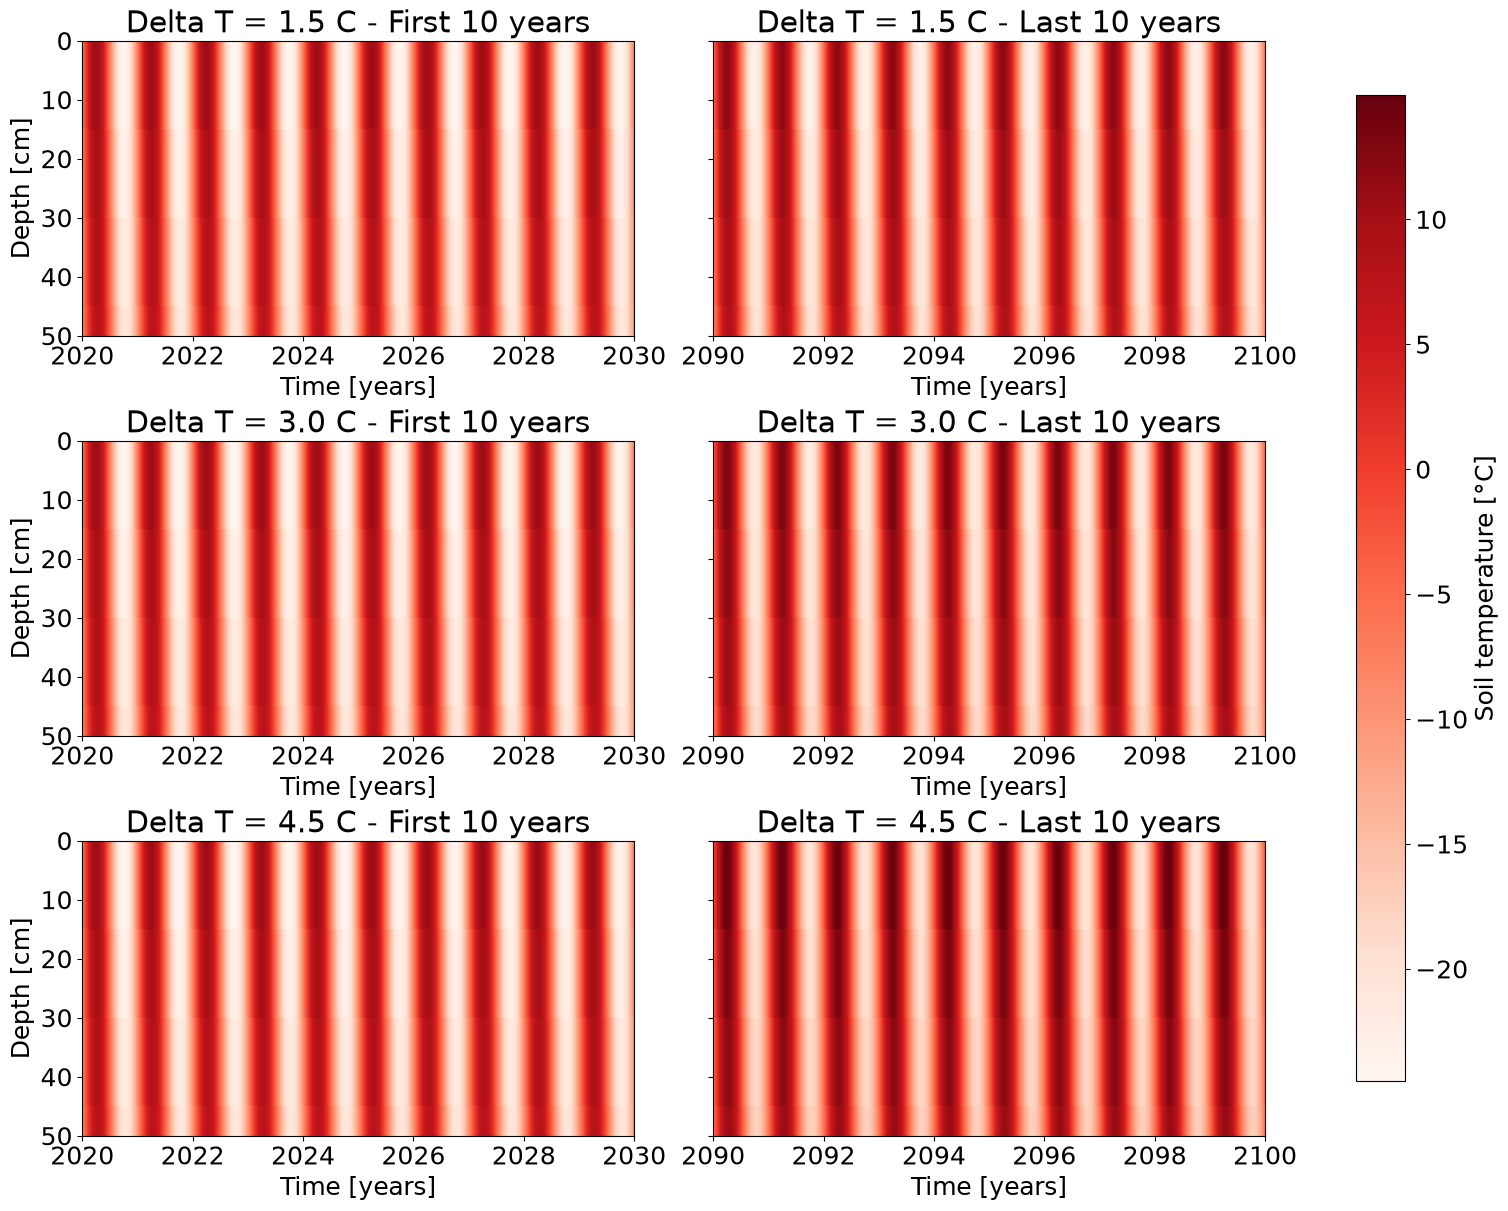

In [13]:
scenario_temperatures = [Ts_15, Ts_30, Ts_45]
scenario_labels = ['Delta T = 1.5 C', 'Delta T = 3.0 C', 'Delta T = 4.5 C']

first_decade = (t >= t[0]) & (t < t[0] + 10.0)
last_decade = (t > t[-1] - 10.0) & (t <= t[-1])
color_min = min(np.min(temperature) for temperature in scenario_temperatures)
color_max = max(np.max(temperature) for temperature in scenario_temperatures)
depths_cm = (np.arange(Nz) + 0.5) * dz * 100.0

fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharey=True, layout='constrained')

for row, (temperature, label) in enumerate(zip(scenario_temperatures, scenario_labels)):
    for column, (time_mask, period_label) in enumerate([(first_decade, 'First 10 years'), (last_decade, 'Last 10 years')]):
        mesh = axes[row, column].pcolormesh(t[time_mask],depths_cm,temperature[:, time_mask],shading='auto',cmap='Reds',vmin=color_min,vmax=color_max)
        axes[row, column].set_title(f'{label} - {period_label}')
        axes[row, column].set_xlabel('Time [years]')
        axes[row, column].set_ylim(50, 0)
        if column == 0:
            axes[row, column].set_ylabel('Depth [cm]')

fig.colorbar(mesh, ax=axes, label='Soil temperature [°C]', shrink=0.9)
plt.show()

## temperature over time at specific depths:

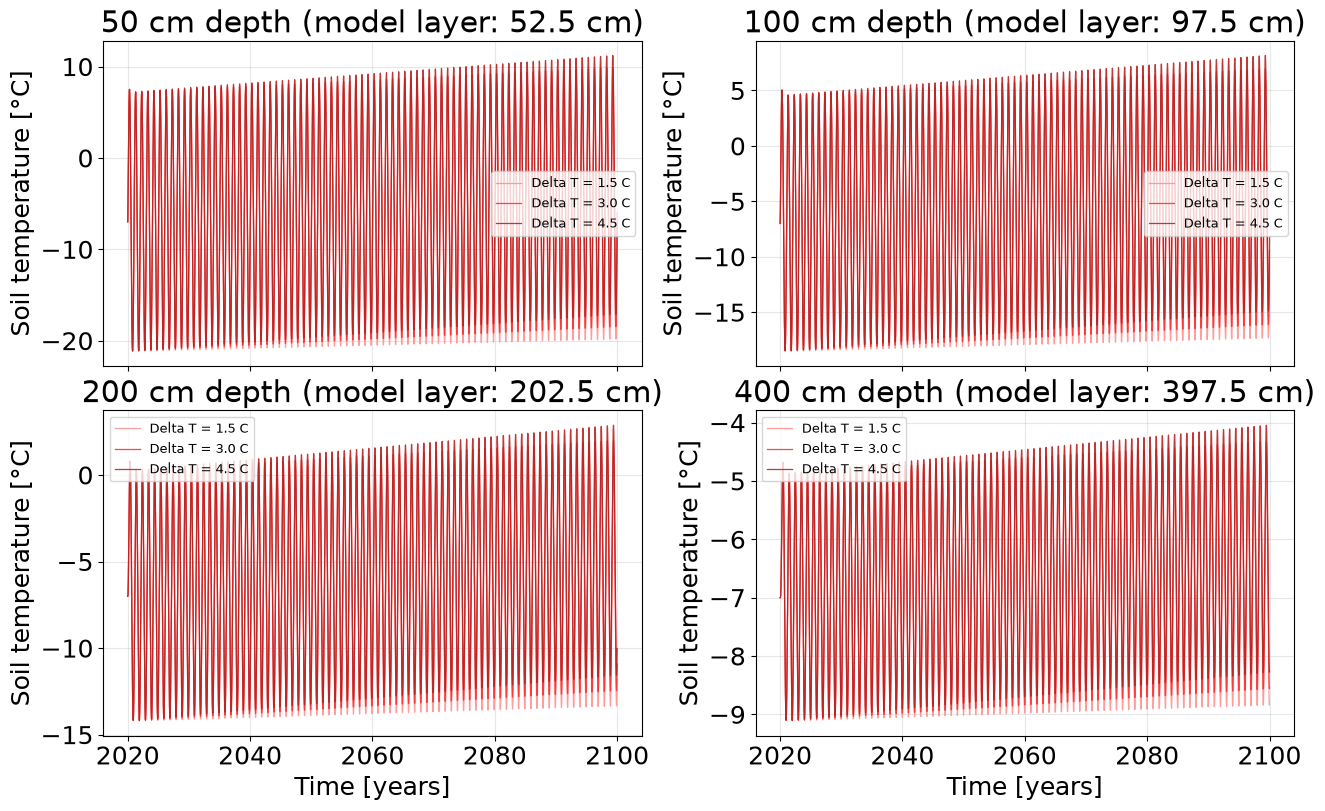

In [14]:
scenario_temperatures = [Ts_15, Ts_30, Ts_45]
scenario_labels = ['Delta T = 1.5 C', 'Delta T = 3.0 C', 'Delta T = 4.5 C']
depths_cm = (np.arange(Nz) + 0.5) * dz * 100.0
target_depths_cm = [50, 100, 200, 400]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, layout='constrained')

for ax, target_depth in zip(axes.flat, target_depths_cm):
    depth_index = np.abs(depths_cm - target_depth).argmin()
    actual_depth = depths_cm[depth_index]

    for temperature, label, color in zip(scenario_temperatures, scenario_labels, scenario_colors):
        ax.plot(t,temperature[depth_index, :],label=label,color=color,linewidth=0.9,alpha=0.9,)
    ax.set_title(f'{target_depth} cm depth (model layer: {actual_depth:.1f} cm)')
    ax.set_ylabel('Soil temperature [°C]')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

for ax in axes[1, :]:
    ax.set_xlabel('Time [years]')

plt.show()

## approximate depth of active layer for each scenario:

In [15]:
scenario_temperatures = [Ts_15, Ts_30, Ts_45]
scenario_labels = ['Delta T = 1.5 C', 'Delta T = 3.0 C', 'Delta T = 4.5 C']
depths_cm = (np.arange(Nz) + 0.5) * dz * 100.0

simulation_start = t[0]
simulation_end = t[-1]
decades = [('First decade', simulation_start, simulation_start + 10.0),('Middle decade', (simulation_start + simulation_end - 10.0) / 2.0,(simulation_start + simulation_end + 10.0) / 2.0),('Final decade', simulation_end - 10.0, simulation_end),]

header = '| Period | ' + ' | '.join(scenario_labels) + ' |'
separator = '|---|' + '---:|' * len(scenario_labels)
table_rows = [header, separator]

for period_label, start_year, end_year in decades:
    time_mask = (t >= start_year) & (t <= end_year)
    depths = []
    for temperature in scenario_temperatures:
        thawed = temperature[:, time_mask] > 0.0
        thawed_depths = np.where(thawed, depths_cm[:, None], 0.0)
        maximum_depth = np.max(thawed_depths)
        depths.append(f'{maximum_depth:.1f} cm')
    table_rows.append(f'| {period_label} ({start_year:.0f}-{end_year:.0f}) | ' + ' | '.join(depths)  + ' |')

display(Markdown('\n'.join(table_rows)))

| Period | Delta T = 1.5 C | Delta T = 3.0 C | Delta T = 4.5 C |
|---|---:|---:|---:|
| First decade (2020-2030) | 217.5 cm | 217.5 cm | 217.5 cm |
| Middle decade (2055-2065) | 217.5 cm | 232.5 cm | 247.5 cm |
| Final decade (2090-2100) | 232.5 cm | 247.5 cm | 277.5 cm |

## is it reasonable to keep the bottom boundary condition fixed?

### I think that it is reasonable to keep the bottom boundary condition fixed because in real life diffusion of heat in soil can only penetrate so far, especially seasonally. 